<a href="https://colab.research.google.com/github/JacekDrzycimski/6tunnel/blob/master/Quaternions_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install pyquaternion

In [2]:
from pyquaternion import Quaternion
import numpy as np

# 1. Create quaternions
# Creating a quaternion representing a 90-degree rotation around the Z-axis
q1 = Quaternion(axis=[0, 0, 1], angle=np.pi/2)
print(f"q1 (90 deg around Z): {q1}")

# 2. Quaternion multiplication (combining rotations)
q2 = Quaternion(axis=[1, 0, 0], angle=np.pi/4) # 45 deg around X-axis
q_combined = q1 * q2
print(f"Combined rotation q_combined: {q_combined}")

# 3. Rotating a vector
v = np.array([1, 0, 0])
v_rotated = q1.rotate(v)
print(f"Vector {v} rotated by q1: {v_rotated}")

# 4. Converting to a rotation matrix
rot_matrix = q1.rotation_matrix
print("Rotation matrix:\n", rot_matrix)

q1 (90 deg around Z): +0.707 +0.000i +0.000j +0.707k
Combined rotation q_combined: +0.653 +0.271i +0.271j +0.653k
Vector [1 0 0] rotated by q1: [2.22044605e-16 1.00000000e+00 0.00000000e+00]
Rotation matrix:
 [[ 1.99673462e-16 -1.00000000e+00  0.00000000e+00]
 [ 1.00000000e+00  1.79380389e-16  0.00000000e+00]
 [ 0.00000000e+00  0.00000000e+00  1.00000000e+00]]


In [3]:
from scipy.spatial.transform import Rotation as R
import numpy as np

# 1. Convert Euler angles to a Quaternion
# Let's define Euler angles: Yaw = 90 deg, Pitch = 45 deg, Roll = 30 deg
# We specify the sequence 'zyx' (commonly used in aerospace/navigation)
euler_degrees = [90, 45, 30]

# Create a rotation object from the Euler angles
r = R.from_euler('zyx', euler_degrees, degrees=True)

# Get the quaternion representation [x, y, z, w]
# Note: SciPy outputs quaternions in [x, y, z, w] format
q_scipy = r.as_quat()
print(f"Euler angles (Yaw/Pitch/Roll): {euler_degrees}")
print(f"Corresponding Quaternion [x, y, z, w]: {q_scipy}\n")

# 2. Convert Quaternion back to Euler angles
# Recreate a rotation object from our quaternion
r_back = R.from_quat(q_scipy)

# Retrieve Euler angles back in the 'zyx' sequence
euler_back = r_back.as_euler('zyx', degrees=True)
print(f"Converted back to Euler angles (Yaw/Pitch/Roll): {euler_back}")

Euler angles (Yaw/Pitch/Roll): [90, 45, 30]
Corresponding Quaternion [x, y, z, w]: [0.43045933 0.09229596 0.70105738 0.56098553]

Converted back to Euler angles (Yaw/Pitch/Roll): [90. 45. 30.]


In [2]:
!pip install -q pyquaternion
import time
from scipy.spatial.transform import Rotation as R
from pyquaternion import Quaternion
import numpy as np

# Number of iterations for our benchmark
N = 50000

print(f"Benchmarking {N} iterations...\n")

# --- 1. PYQUATERNION BENCHMARK ---
start_time = time.time()
for _ in range(N):
    # Create quaternion and rotate vector
    q = Quaternion(axis=[0, 0, 1], angle=np.pi/2)
    v_rot = q.rotate([1.0, 0.0, 0.0])
pyquat_time = time.time() - start_time
print(f"pyquaternion time: {pyquat_time:.4f} seconds")

# --- 2. SCIPY BENCHMARK ---
start_time = time.time()
for _ in range(N):
    # Create rotation object and rotate vector
    r = R.from_euler('z', 90, degrees=True)
    v_rot = r.apply([1.0, 0.0, 0.0])
scipy_time = time.time() - start_time
print(f"SciPy (individual loops) time: {scipy_time:.4f} seconds")

# --- 3. SCIPY BATCHED BENCHMARK (The vectorized way) ---
# SciPy shines when batching computations instead of looping in Python
start_time = time.time()
angles = np.ones(N) * 90
vectors = np.tile([1.0, 0.0, 0.0], (N, 1))
r_batch = R.from_euler('z', angles, degrees=True)
v_rot_batch = r_batch.apply(vectors)
scipy_batch_time = time.time() - start_time
print(f"SciPy (batched/vectorized) time: {scipy_batch_time:.4f} seconds")

# Print speedup
print(f"\nBatched SciPy is {pyquat_time / scipy_batch_time:.1f}x faster than pyquaternion!")

Benchmarking 50000 iterations...

pyquaternion time: 0.8970 seconds
SciPy (individual loops) time: 0.2791 seconds
SciPy (batched/vectorized) time: 0.0040 seconds

Batched SciPy is 221.9x faster than pyquaternion!


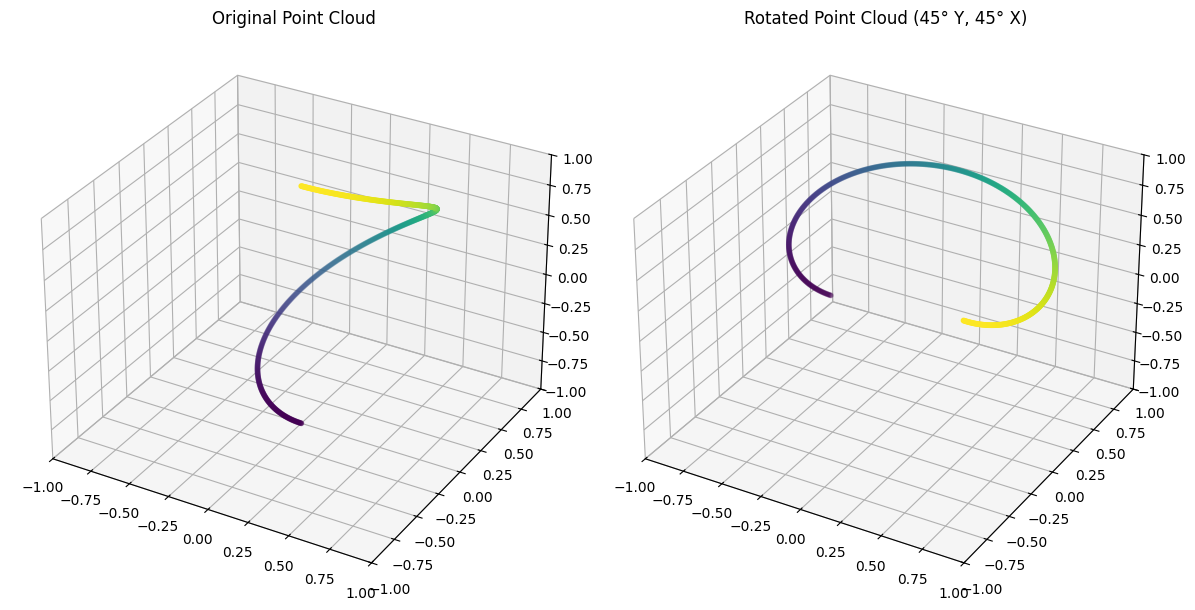

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.transform import Rotation as R

# 1. Generate a synthetic point cloud (a 3D hemisphere)
n_points = 500
theta = np.linspace(0, np.pi, n_points)
phi = np.linspace(0, np.pi, n_points)

x = np.sin(theta) * np.cos(phi)
y = np.sin(theta) * np.sin(phi)
z = np.cos(theta)

# Stack coordinates to form an (N, 3) point cloud array
point_cloud = np.vstack((x, y, z)).T

# 2. Define the rotation (e.g., 45 degrees around Y, 45 degrees around X)
rotation = R.from_euler('yx', [45, 45], degrees=True)

# 3. Apply the rotation to the entire point cloud in a single vectorized step
rotated_point_cloud = rotation.apply(point_cloud)

# 4. Visualize the original and rotated point clouds
fig = plt.figure(figsize=(12, 6))

# Subplot 1: Original Point Cloud
ax1 = fig.add_subplot(121, projection='3d')
ax1.scatter(point_cloud[:, 0], point_cloud[:, 1], point_cloud[:, 2], c=z, cmap='viridis', s=10)
ax1.set_title("Original Point Cloud")
ax1.set_xlim([-1, 1]); ax1.set_ylim([-1, 1]); ax1.set_zlim([-1, 1])

# Subplot 2: Rotated Point Cloud
ax2 = fig.add_subplot(122, projection='3d')
ax2.scatter(rotated_point_cloud[:, 0], rotated_point_cloud[:, 1], rotated_point_cloud[:, 2], c=z, cmap='viridis', s=10)
ax2.set_title("Rotated Point Cloud (45° Y, 45° X)")
ax2.set_xlim([-1, 1]); ax2.set_ylim([-1, 1]); ax2.set_zlim([-1, 1])

plt.tight_layout()
plt.show()

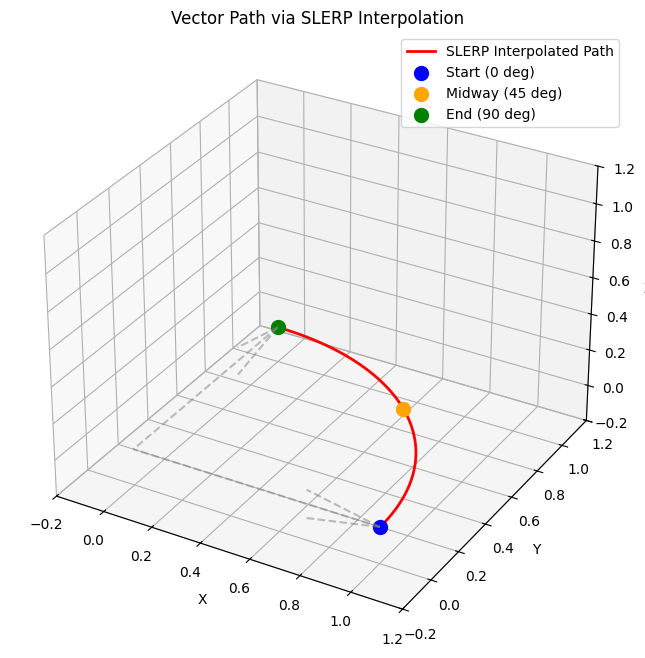

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.transform import Rotation as R
from scipy.spatial.transform import Slerp

# 1. Define key rotations (starting at 0 degrees, ending at 90 degrees around Z-axis)
key_times = [0, 1]  # The interval over which to interpolate
key_rotations = R.from_euler('z', [0, 90], degrees=True)

# 2. Initialize the SLERP object
slerp = Slerp(key_times, key_rotations)

# 3. Interpolate rotations at 50 intermediate steps between time 0 and 1
interpolated_times = np.linspace(0, 1, 50)
interpolated_rotations = slerp(interpolated_times)

# 4. Let's see how a single vector [1, 0, 0] rotates over time
initial_vector = np.array([1, 0, 0])
path_vectors = interpolated_rotations.apply(initial_vector)

# 5. Plot the path of the rotating vector
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')

# Plot the trajectory path
ax.plot(path_vectors[:, 0], path_vectors[:, 1], path_vectors[:, 2], 'r-', label='SLERP Interpolated Path', linewidth=2)

# Highlight the start, middle, and end points
ax.scatter(path_vectors[0, 0], path_vectors[0, 1], path_vectors[0, 2], color='blue', s=100, label='Start (0 deg)')
ax.scatter(path_vectors[25, 0], path_vectors[25, 1], path_vectors[25, 2], color='orange', s=100, label='Midway (45 deg)')
ax.scatter(path_vectors[-1, 0], path_vectors[-1, 1], path_vectors[-1, 2], color='green', s=100, label='End (90 deg)')

# Coordinate axes for context
ax.quiver(0, 0, 0, 1, 0, 0, color='gray', linestyle='--', alpha=0.5)
ax.quiver(0, 0, 0, 0, 1, 0, color='gray', linestyle='--', alpha=0.5)

ax.set_title("Vector Path via SLERP Interpolation")
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_xlim([-0.2, 1.2]); ax.set_ylim([-0.2, 1.2]); ax.set_zlim([-0.2, 1.2])
ax.legend()
plt.show()

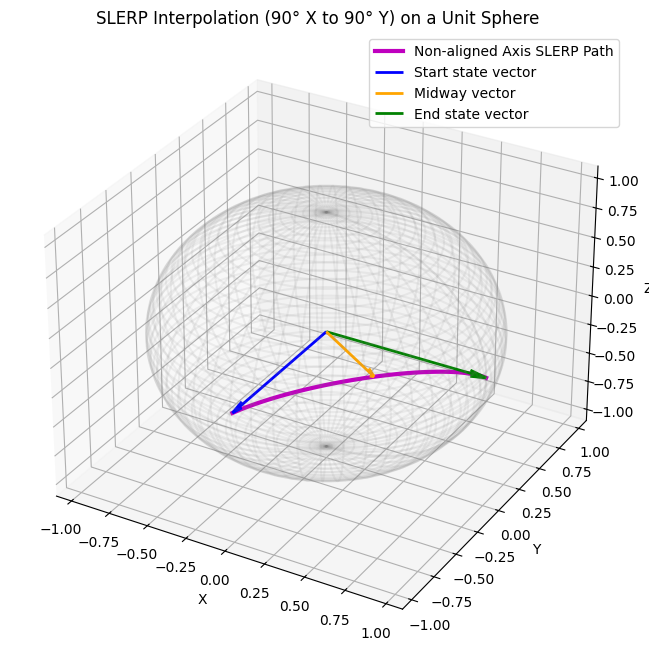

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.transform import Rotation as R
from scipy.spatial.transform import Slerp

# 1. Define non-aligned rotations at key times t=0 and t=1
# Start: 90 degrees around X-axis
# End: 90 degrees around Y-axis
key_times = [0, 1]
key_rotations = R.from_euler('xyz', [[90, 0, 0], [0, 90, 0]], degrees=True)

# 2. Initialize SLERP
slerp = Slerp(key_times, key_rotations)

# 3. Interpolate 100 points between t=0 and t=1
interpolated_times = np.linspace(0, 1, 100)
interpolated_rotations = slerp(interpolated_times)

# 4. Apply the interpolated rotations to a base vector [0, 0, 1]
initial_vector = np.array([0, 0, 1])
path_vectors = interpolated_rotations.apply(initial_vector)

# 5. Visualize the 3D trajectory
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')

# Plot the smooth interpolated arc trajectory
ax.plot(path_vectors[:, 0], path_vectors[:, 1], path_vectors[:, 2], 'm-', label='Non-aligned Axis SLERP Path', linewidth=3)

# Plot start, midway, and end vector positions
ax.quiver(0, 0, 0, path_vectors[0, 0], path_vectors[0, 1], path_vectors[0, 2], color='blue', arrow_length_ratio=0.1, linewidth=2, label='Start state vector')
ax.quiver(0, 0, 0, path_vectors[50, 0], path_vectors[50, 1], path_vectors[50, 2], color='orange', arrow_length_ratio=0.1, linewidth=2, label='Midway vector')
ax.quiver(0, 0, 0, path_vectors[-1, 0], path_vectors[-1, 1], path_vectors[-1, 2], color='green', arrow_length_ratio=0.1, linewidth=2, label='End state vector')

# Plot the unit sphere grid outline for spatial context
u = np.linspace(0, 2 * np.pi, 100)
v = np.linspace(0, np.pi, 100)
sphere_x = np.outer(np.cos(u), np.sin(v))
sphere_y = np.outer(np.sin(u), np.sin(v))
sphere_z = np.outer(np.ones(np.size(u)), np.cos(v))
ax.plot_wireframe(sphere_x, sphere_y, sphere_z, color='gray', alpha=0.1)

ax.set_title("SLERP Interpolation (90° X to 90° Y) on a Unit Sphere")
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_xlim([-1.1, 1.1])
ax.set_ylim([-1.1, 1.1])
ax.set_zlim([-1.1, 1.1])
ax.legend()
plt.show()